# Hands-on 23 (Bab 9): Membandingkan Threshold Statis vs Model Anomaly Detection

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 9.

Dua pendekatan umum IoT dibandingkan terhadap ground truth: threshold statis
(current > 10 A) dan Isolation Forest. Tujuannya memahami kapan threshold cukup
dan kapan model ML memberi nilai tambah.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Threshold Statis

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/current_threshold_detection.py"], capture_output=True, text=True)
print(r.stdout)

=== Threshold Detection (current > 10.0 A) ===
threshold_anomaly
0    485
1     15

Confusion Matrix:
[[485   0]
 [  0  15]]

Classification Report:
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00       485
     anomaly       1.00      1.00      1.00        15

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500

[SUKSES] outputs/reports/current_threshold_results.csv



## 2. Perbandingan Metrik

In [3]:
r = subprocess.run([sys.executable, "scripts/compare_threshold_vs_iforest.py"], capture_output=True, text=True)
print(r.stdout)

=== Perbandingan Threshold vs Isolation Forest ===
         method  accuracy  precision  recall  f1
      Threshold       1.0        1.0     1.0 1.0
IsolationForest       1.0        1.0     1.0 1.0

[SUKSES] outputs/reports/threshold_vs_iforest.csv



## 3. Visualisasi F1 dan Recall

[SUKSES] outputs/figures/threshold_vs_iforest_f1.png
[SUKSES] outputs/figures/threshold_vs_iforest_recall.png



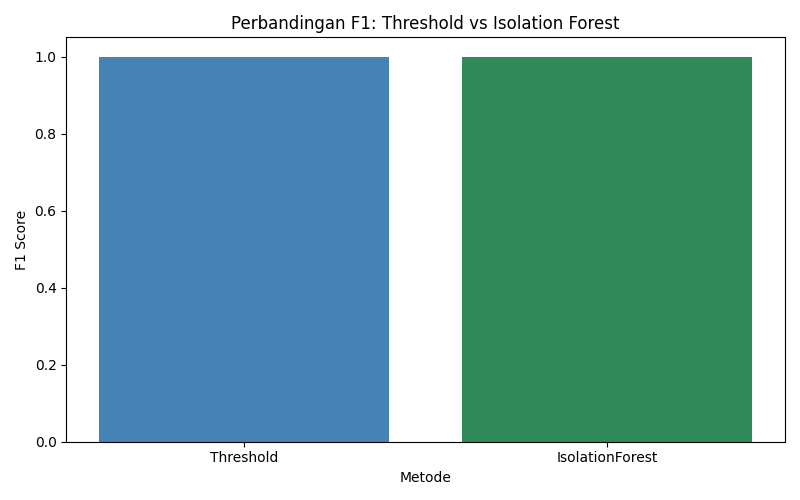

In [4]:
r = subprocess.run([sys.executable, "scripts/plot_threshold_vs_iforest.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/threshold_vs_iforest_f1.png")

## Penutup

Pada dataset ini kedua metode sama-sama sempurna (F1 = 1.00) karena anomali buatan
berupa lonjakan 4-8 A sangat jelas dari satu ambang. Pada data nyata anomali lebih
halus: threshold cocok untuk alarm cepat yang sangat jelas, Isolation Forest untuk
pola multivariat yang halus, dan kombinasi keduanya sering paling masuk akal.
Hasil tersimpan di `outputs/reports/threshold_vs_iforest.csv`.